# Eksploracja danych - recenzje aplikacji z Google Play

Cel notatnika: poznać zbiór treningowy z Kaggle, zanim zbudujemy model.

1. Wczytanie danych i podstawowe informacje
2. Rozkład ocen (gwiazdek)
3. Zamiana ocen na etykiety sentymentu i balans klas
4. Długość recenzji
5. Najczęstsze słowa w recenzjach pozytywnych i negatywnych
6. Przykładowe recenzje
7. Recenzje w czasie (jeśli zbiór ma daty)
8. Podsumowanie

**Uruchomienie:** w VS Code wybierz kernel z `.venv` (prawy górny róg) i kliknij *Run All*.

In [30]:
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# notatnik leży w folderze notebooks/, a moduły w src/ - dodajemy główny folder projektu do ścieżki
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_DIR))

from src.preprocessing import RAW_DIR, LABEL_NAMES, clean_text, load_raw_data, prepare_dataset, score_to_label

pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.figsize"] = (8, 4)
COLORS = {"pozytywny": "#1b9e77", "negatywny": "#d95f02", "neutralny (3★)": "#999999"}

## 1. Wczytanie danych

In [31]:
csv_files = sorted(RAW_DIR.glob("*.csv"))
print("Pliki w data/raw:", [f.name for f in csv_files])

# pełny pierwszy plik - żeby zobaczyć wszystkie kolumny, jakie daje Kaggle
full = pd.read_csv(csv_files[0], low_memory=False)
print("Wymiary:", full.shape)
full.head()

Pliki w data/raw: ['reviews.csv']
Wymiary: (12495, 12)


,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,sortOrder,appId
0,gp:AOqpTOEhZuqSqqWnaKRgv-9ABYdajFUB0WugPGh-SG-fgH355YH_t7J2q4xYo6ZzN3Mc7iSrrTV6ke8hG_fl4Q,Eric Tie,https://play-lh.googleusercontent.com/a-/AOh14GiGET2XHTvsSEsA07ZBPu2s1E6fOXd9WyT_ahChpw,I cannot open the app anymore,1,0,5.4.0.6,2020-10-27 21:24:41,NaN,NaN,newest,com.anydo
1,gp:AOqpTOH0WP4IQKBZ2LrdNmFy_YmpPCVrV3diEU9KGm3fAX6VG0NAZCudCQpQRRI3GLL_tr8DQzUTP1hrOYG74A,john alpha,https://play-lh.googleusercontent.com/a-/AOh14GjpfgjOEbD3brypMeMT3KvhYlWG_nO2bMnMIfY9,I have been begging for a refund from this app for over a month and nobody is replying me,1,0,NaN,2020-10-27 14:03:28,"Please note that from checking our records, your email has been answered, and there was no subscription registered u...",2020-10-27 15:05:52,newest,com.anydo
2,gp:AOqpTOEMCkJB8Iq1p-r9dPwnSYadA5BkPWTf32Z1azuuTvqA9KWdTQqNNXWZsJEhmSuYUY_LmL-OdUIl4j70wg,Sudhakar .S,https://play-lh.googleusercontent.com/a-/AOh14GidHUHTvHZTXBX36CdxFeccVR2IasC1MHUHXLuFpg,Very costly for the premium version (approx Indian Rupees 910 per year). Better to download the premium version of t...,1,0,NaN,2020-10-27 08:18:40,NaN,NaN,newest,com.anydo
3,gp:AOqpTOGFrUWuKGycpje8kszj3uwHN6tU_fd4gLVFy9z7hfGM7Gan22TJrN89NmGVEdj5o4U6W4I6slbTx8OsQw,SKGflorida@bellsouth.net DAVID S,https://play-lh.googleusercontent.com/-75aK0WFniac/AAAAAAAAAAI/AAAAAAAAAAA/AMZuucn_nhfTJ2FT63nZ53feI1vVx58DJg/photo.jpg,"Used to keep me organized, but all the 2020 UPDATES have made a mess of things !!! Y cudn't u leave well enuf alone ...",1,0,NaN,2020-10-26 13:28:07,"What do you find troublesome about the update? We'd love to get your feedback, by writing to us at https://www.any.d...",2020-10-26 14:58:29,newest,com.anydo
4,gp:AOqpTOHls7DW8wmDFzTkHwxuqFkdNQtKHmO6Pt9jhZEQ0Q2rDzcc9WMABIXZNu0pIJOhiFrA4uhMOLq1ZIWKQA,Louann Stoker,https://play-lh.googleusercontent.com/-pBcY_Z-qfB4/AAAAAAAAAAI/AAAAAAAAAAA/AMZuuclb31oz9DIIm_ibRaVH8B2uF2SVZw/photo.jpg,Dan Birthday Oct 28,1,0,5.6.0.7,2020-10-26 06:10:50,NaN,NaN,newest,com.anydo


In [32]:
full.info()

<class 'pandas.DataFrame'>
RangeIndex: 12495 entries, 0 to 12494
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   reviewId              12495 non-null  str  
 1   userName              12495 non-null  str  
 2   userImage             12495 non-null  str  
 3   content               12495 non-null  str  
 4   score                 12495 non-null  int64
 5   thumbsUpCount         12495 non-null  int64
 6   reviewCreatedVersion  10333 non-null  str  
 7   at                    12495 non-null  str  
 8   replyContent          5818 non-null   str  
 9   repliedAt             5818 non-null   str  
 10  sortOrder             12495 non-null  str  
 11  appId                 12495 non-null  str  
dtypes: int64(2), str(10)
memory usage: 7.1 MB


In [33]:
# dane w ujednoliconym formacie: kolumny text i score (ze wszystkich plików CSV)
raw = load_raw_data()
print("Liczba recenzji:", len(raw))
print("Braki danych:")
print(raw[["text", "score"]].isna().sum())
print("Duplikaty treści:", raw["text"].duplicated().sum())

[wczytano] reviews.csv: 12495 wierszy
Liczba recenzji: 12495
Braki danych:
text     0
score    0
dtype: int64
Duplikaty treści: 688


## 2. Rozkład ocen (gwiazdek)

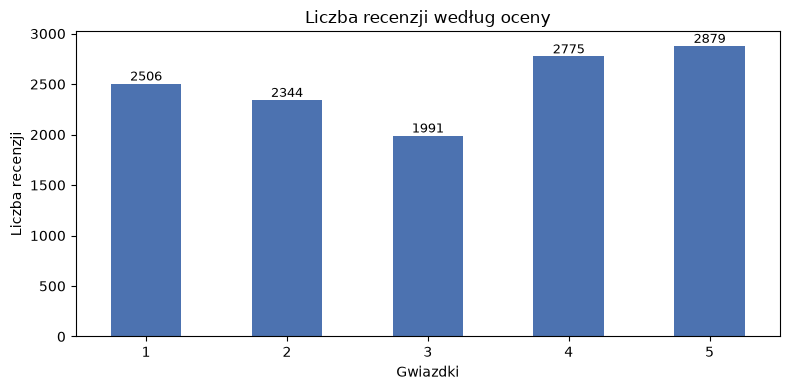

score
1    20.1
2    18.8
3    15.9
4    22.2
5    23.0
Name: % recenzji, dtype: float64

In [34]:
stars = raw["score"].value_counts().sort_index()
ax = stars.plot(kind="bar", color="#4c72b0", rot=0)
ax.set_title("Liczba recenzji według oceny")
ax.set_xlabel("Gwiazdki")
ax.set_ylabel("Liczba recenzji")
for i, v in enumerate(stars.values):
    ax.text(i, v, f"{v}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

(stars / stars.sum() * 100).round(1).rename("% recenzji")

## 3. Etykiety sentymentu i balans klas

Zasada: **1-2 gwiazdki -> negatywny**, **4-5 gwiazdki -> pozytywny**, **3gwiazdki -> odrzucamy** (opinie mieszane, niejednoznaczne).

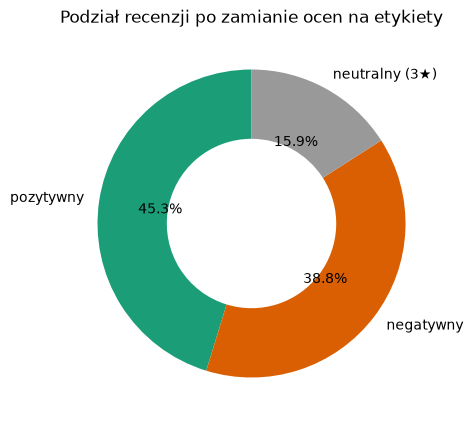

score
pozytywny         5654
negatywny         4850
neutralny (3★)    1991
Name: count, dtype: int64

In [35]:
mapped = raw["score"].apply(score_to_label).map(LABEL_NAMES).fillna("neutralny (3★)")
counts = mapped.value_counts()

fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90,
       colors=[COLORS[c] for c in counts.index], wedgeprops=dict(width=0.45))
ax.set_title("Podział recenzji po zamianie ocen na etykiety")
plt.show()
counts

In [36]:
data = prepare_dataset(raw)   # to samo czyszczenie, którego używa src/train.py
balance = data["label"].map(LABEL_NAMES).value_counts()
print(f"Po czyszczeniu (bez 3★, pustych i duplikatów): {len(data)} recenzji")
print(balance)
print(f"Stosunek klas pozytywne/negatywne: {balance.get('pozytywny', 0) / max(balance.get('negatywny', 1), 1):.2f}")

Po czyszczeniu (bez 3★, pustych i duplikatów): 9659 recenzji
label
pozytywny    4930
negatywny    4729
Name: count, dtype: int64
Stosunek klas pozytywne/negatywne: 1.04


## 4. Długość recenzji

            count  mean   std  min   25%   50%   75%    max
sentiment                                                  
negatywny  4729.0  32.1  28.6  1.0  11.0  23.0  46.0  257.0
pozytywny  4930.0  25.3  26.9  1.0   7.0  16.0  35.0  739.0


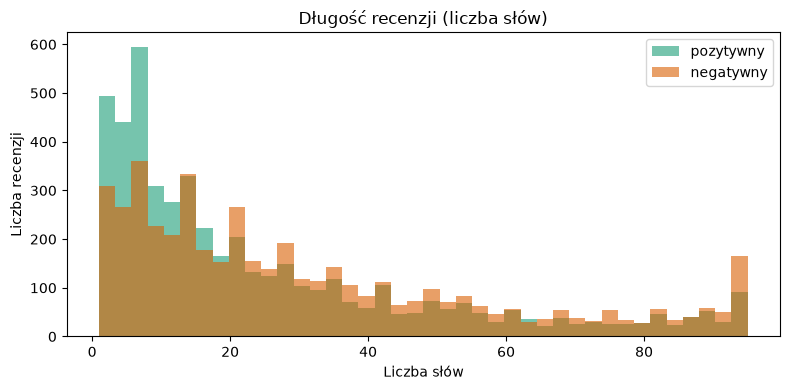

In [37]:
data["sentiment"] = data["label"].map(LABEL_NAMES)
data["n_words"] = data["clean_text"].str.split().str.len()

print(data.groupby("sentiment")["n_words"].describe().round(1))

fig, ax = plt.subplots()
upper = data["n_words"].quantile(0.98)   # obcinamy skrajne wartości dla czytelności
for sent in ["pozytywny", "negatywny"]:
    ax.hist(data.loc[data["sentiment"] == sent, "n_words"].clip(upper=upper),
            bins=40, alpha=0.6, label=sent, color=COLORS[sent])
ax.set_title("Długość recenzji (liczba słów)")
ax.set_xlabel("Liczba słów")
ax.set_ylabel("Liczba recenzji")
ax.legend()
plt.tight_layout()
plt.show()

In [38]:
short = (data["n_words"] <= 3).mean()
print(f"Recenzje bardzo krótkie (<= 3 słowa): {short:.1%}")
data.loc[data["n_words"] <= 3, ["text", "sentiment"]].sample(min(10, (data['n_words'] <= 3).sum()), random_state=0)

Recenzje bardzo krótkie (<= 3 słowa): 8.3%


,text,sentiment
58,Work on it,negatywny
6701,Pe rfect management,pozytywny
7008,Купил версию Pro. Сменился телефон. Что покупать снова? Тогда зачем такое приложение?,negatywny
1124,Premium or nothing.,negatywny
2217,Best in class,pozytywny
7637,Dose not work,negatywny
6930,Useless without pro.,negatywny
8869,Easy and clear,pozytywny
8470,55 o,negatywny
1226,So helpful tool.,pozytywny


## 5. Najczęstsze słowa

Pomijamy typowe słowa funkcyjne (*the, and, is…*), ale **zostawiamy przeczenia** (*not, no, never*),
bo zmieniają sentyment zdania.

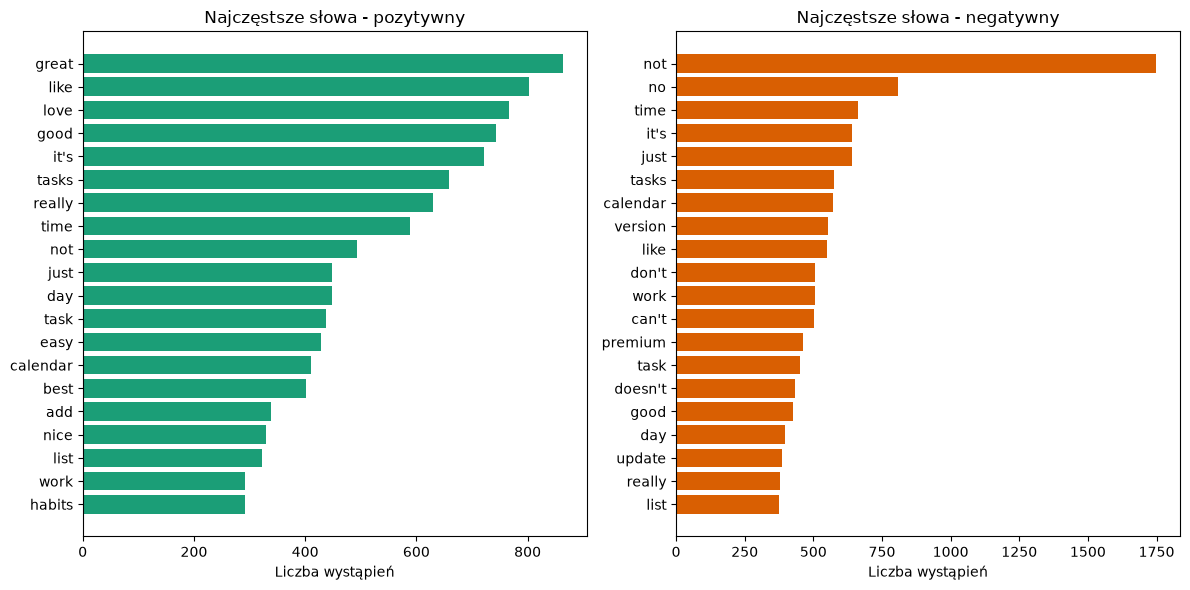

In [39]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

NEGATIONS = {"not", "no", "never", "nor", "cannot", "nothing", "none"}
STOP = (set(ENGLISH_STOP_WORDS) - NEGATIONS) | {"app", "apps", "s", "t", "im", "ve", "ll", "d", "m", "use", "using"}

def top_words(texts, n=20):
    cnt = Counter(w for t in texts for w in t.split() if w not in STOP and len(w) > 1)
    return cnt.most_common(n)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, sent in zip(axes, ["pozytywny", "negatywny"]):
    words, freqs = zip(*top_words(data.loc[data["sentiment"] == sent, "clean_text"]))
    ax.barh(words[::-1], freqs[::-1], color=COLORS[sent])
    ax.set_title(f"Najczęstsze słowa - {sent}")
    ax.set_xlabel("Liczba wystąpień")
plt.tight_layout()
plt.show()

Słowa **najbardziej charakterystyczne** dla klasy - częste w jednej klasie i rzadkie w drugiej (stosunek względnych częstości):

In [40]:
import numpy as np

def word_freq(texts):
    cnt = Counter(w for t in texts for w in set(t.split()) if w not in STOP and len(w) > 1)
    return pd.Series(cnt) / len(texts)   # odsetek recenzji zawierających słowo

pos_f = word_freq(data.loc[data["sentiment"] == "pozytywny", "clean_text"])
neg_f = word_freq(data.loc[data["sentiment"] == "negatywny", "clean_text"])
freq = pd.concat([pos_f, neg_f], axis=1, keys=["pozytywny", "negatywny"]).fillna(0)
freq = freq[(freq.max(axis=1) >= 0.005)]       # tylko słowa w min. 0,5% recenzji jednej z klas
freq["log_ratio"] = np.log2((freq["pozytywny"] + 1e-3) / (freq["negatywny"] + 1e-3))

pd.concat([
    freq.sort_values("log_ratio", ascending=False).head(15).index.to_series(name="pozytywne").reset_index(drop=True),
    freq.sort_values("log_ratio").head(15).index.to_series(name="negatywne").reset_index(drop=True),
], axis=1)

,pozytywne,negatywne
0,helps,useless
1,helped,uninstalled
2,amazing,disappointed
3,loving,uninstalling
4,helpful,sign
5,life,uninstall
6,thank,refund
7,highly,login
8,best,restore
9,excellent,deleted


## 6. Przykładowe recenzje dla każdej oceny

In [41]:
for s in sorted(raw["score"].dropna().unique()):
    print(f"===== {int(s)} gwiazdka =====")
    sample = raw.loc[raw["score"] == s, "text"].dropna()
    for t in sample.sample(min(3, len(sample)), random_state=1):
        print("-", str(t)[:200])
    print()

===== 1 gwiazdka =====
- The Ads now pop-up full screen. That is very, very, very, very annoying. What if I'm on an important call making an appointment and then you pop-up this irrelevant ad right in my face. Unprofessional.
- This app is not working!!!! 🤨
- This app changed the password I had and I don't know what it is what do I do?

===== 2 gwiazdka =====
- I have enough Google Play Credits for Pro Version but while making payment a lower amount is shown. What's the problem?
- Not very intuitive. I couldn't find a way to switch between week, day, or month views.
- Recurring reminders are available for free in Google reminder. You can't Monetize the basic functions.

===== 3 gwiazdka =====
- The new video ad is really annoying, it pops out, and no way to close it unless you close the entire app. It really interrupt when you want to add a few appointments to the calendar.
- Too much paid only
- The best app around for tracking habits. But the artificial limitation to 5 habits in the 

## 7. Recenzje w czasie

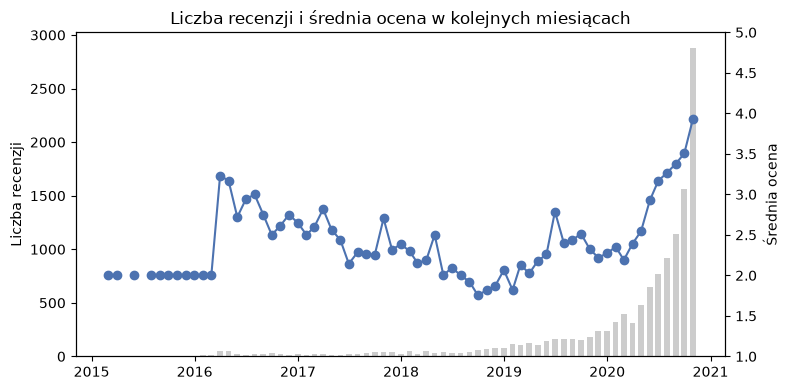

In [42]:
date_col = next((c for c in ["at", "date", "Date", "review_date"] if c in full.columns), None)
if date_col is None:
    print("Zbiór nie ma kolumny z datą - pomijam.")
else:
    d = full[[date_col, "score"]].copy()
    d[date_col] = pd.to_datetime(d[date_col], errors="coerce")
    d = d.dropna()
    monthly = d.set_index(date_col).resample("ME")["score"].agg(["count", "mean"])
    fig, ax1 = plt.subplots()
    ax1.bar(monthly.index, monthly["count"], width=20, color="#cccccc", label="Liczba recenzji")
    ax1.set_ylabel("Liczba recenzji")
    ax2 = ax1.twinx()
    ax2.plot(monthly.index, monthly["mean"], color="#4c72b0", marker="o", label="Średnia ocena")
    ax2.set_ylabel("Średnia ocena")
    ax2.set_ylim(1, 5)
    ax1.set_title("Liczba recenzji i średnia ocena w kolejnych miesiącach")
    fig.tight_layout()
    plt.show()

## 8. Podsumowanie

In [43]:
print(f"Recenzji w surowym zbiorze:          {len(raw)}")
print(f"Recenzji użytych do treningu:        {len(data)}")
print(f"Odrzucone 3 gwiazdki / puste / duplikaty:    {len(raw) - len(data)}")
for k, v in balance.items():
    print(f"  {k:12s} {v:6d}  ({v / len(data):.1%})")
print(f"Mediana długości recenzji:           {data['n_words'].median():.0f} słów")
print(f"Bardzo krótkie recenzje (<= 3 słowa): {short:.1%}")

Recenzji w surowym zbiorze:          12495
Recenzji użytych do treningu:        9659
Odrzucone 3 gwiazdki / puste / duplikaty:    2836
  pozytywny      4930  (51.0%)
  negatywny      4729  (49.0%)
Mediana długości recenzji:           19 słów
Bardzo krótkie recenzje (<= 3 słowa): 8.3%


**Wnioski dla modelu:**
- recenzje są krótkie i potoczne -> wystarczy prosty model TF-IDF; bigramy pomagają złapać przeczenia (*not good*),
- nie usuwamy przeczeń przy czyszczeniu tekstu